# Análisis de las correcciones de la Fase 1

Proyecto integrador de Modelos y Simulación de Sistemas I (Universidad de Antioquia).

Este notebook responde a las correcciones C1, C2, C3 y C5 de la retroalimentación de la Fase 1 y deja la evidencia para que el equipo decida la estrategia de partición y la sexta predictora. No toma esas decisiones ni entrena un modelo nuevo.

Reutiliza `src/data.py`, `src/features.py`, `src/pipeline.py` y `src/splitting.py`. Los análisis que miran `vote_average` se hacen solo con entrenamiento. Los conteos de estructura (colecciones, fechas y filas por filtro) sí usan todo el dataset, porque no miran el objetivo.

Para ejecutarlo hacen falta `fase-2/requirements.txt` y `fase-2/requirements-notebook.txt`.

El análisis se hizo antes de la decisión del equipo y compara las dos opciones. Por eso fija `es_franquicia` de forma explícita donde compara con la Fase 1, aunque el default de `src/config.py` ahora es `es_secuela`. También fija `early_stopping="auto"`, la configuración de la Fase 1, porque desde el Paso 3 el default es `False`. Las métricas finales del modelo están en la sección "Paso 3 – Entrenamiento" de `docs/decisiones.md`.

**Estructura.**

1. EDA complementario (C1)
2. Sagas compartidas (C2)
3. `es_franquicia` al momento del estreno (C3)
4. Horizonte del objetivo (C5)
5. Sensibilidad a la semilla
6. Resumen para la decisión del equipo

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

RAIZ_FASE2 = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(RAIZ_FASE2))

from src import config, data, features, pipeline, splitting

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

COLOR_PRINCIPAL = "#2a78d6"
plt.rcParams.update({
    "figure.dpi": 90,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

El CSV se busca en `fase-2/data/` y, si no está ahí, en la carpeta `data/` de la raíz, que es la de la Fase 1.

In [2]:
candidatos = [
    RAIZ_FASE2 / "data" / config.DATASET_FILE,
    RAIZ_FASE2.parent / "data" / config.DATASET_FILE,
]
RUTA_CSV = next((ruta for ruta in candidatos if ruta.is_file()), None)
if RUTA_CSV is None:
    raise FileNotFoundError("Falta movies_metadata.csv: ver fase-2/data/README.md")

crudo = data.read_raw_csv(RUTA_CSV)
limpio = features.add_sequel_feature(data.clean_data(crudo))  # antes de los filtros
filtrado = data.apply_filters(limpio, config.MIN_VOTES)
df = features.derive_features(filtrado)

print(f"Crudo: {len(crudo):,} | Limpio: {len(limpio):,} | Población: {len(df):,}")

Crudo: 45,466 | Limpio: 45,430 | Población: 21,656


### Particiones y comprobación contra la Fase 1

La estrategia `random` debe dar exactamente el modelo de la Fase 1. Si esta celda falla, nada de lo que sigue es comparable.

In [3]:
train_r, test_r = splitting.split_data(df, "random", config.TEST_SIZE, config.SEED)
train_g, test_g = splitting.split_data(df, "group", config.TEST_SIZE, config.SEED)

SEXTA_FASE1 = "es_franquicia"
COLUMNAS = list(config.get_feature_names(SEXTA_FASE1))


def hgb_paso2(semilla, sexta):
    """HGB tal como se evaluó en este análisis: con la parada temprana de la Fase 1."""
    return pipeline.build_pipeline(semilla, sexta).set_params(modelo__early_stopping="auto")


OBJETIVO = config.TARGET

modelo_r = hgb_paso2(config.SEED, SEXTA_FASE1).fit(train_r[COLUMNAS], train_r[OBJETIVO])
modelo_fase1 = joblib.load(RAIZ_FASE2.parent / "fase-1" / "models" / "modelo_vote_average.joblib")
pred_r = modelo_r.predict(test_r[COLUMNAS])
assert np.allclose(pred_r, modelo_fase1.predict(test_r[COLUMNAS]))
print("Las predicciones de 'random' coinciden con el .joblib de la Fase 1:", len(pred_r), "películas de prueba")

Las predicciones de 'random' coinciden con el .joblib de la Fase 1: 4332 películas de prueba


## 1. EDA complementario (C1)

Esta sección usa el train de la partición `random`, que es la de la Fase 1. La última columna de la tabla de 1.2 repite la correlación con el train por grupos para comprobar que la conclusión no depende de esa elección.

### 1.1 Correlaciones entre las predictoras numéricas

In [4]:
NUMERICAS = list(config.NUMERIC_FEATURES)

pearson = train_r[NUMERICAS].corr(method="pearson")
spearman = train_r[NUMERICAS].corr(method="spearman")
pares = train_r[NUMERICAS].notna().astype(int)
n_pares = pares.T.dot(pares)

print("Pearson"); print(pearson.round(3).to_string())
print("\nSpearman"); print(spearman.round(3).to_string())
print("\nPares con ambos datos"); print(n_pares.to_string())

Pearson
              budget  runtime  release_year
budget         1.000    0.217         0.219
runtime        0.217    1.000         0.079
release_year   0.219    0.079         1.000

Spearman
              budget  runtime  release_year
budget         1.000    0.323         0.169
runtime        0.323    1.000        -0.018
release_year   0.169   -0.018         1.000

Pares con ambos datos
              budget  runtime  release_year
budget          5962     5944          5962
runtime         5944    17161         17158
release_year    5962    17158         17321


No hay redundancia entre las tres predictoras numéricas. La relación más fuerte es entre `budget` y `runtime` (Pearson 0,217, Spearman 0,323), y `runtime` y `release_year` casi no se relacionan. Ninguna es candidata a eliminarse por repetir información. Las correlaciones con `budget` usan solo unas 5.950 películas, las que lo tienen reportado.

### 1.2 Relación con `vote_average`

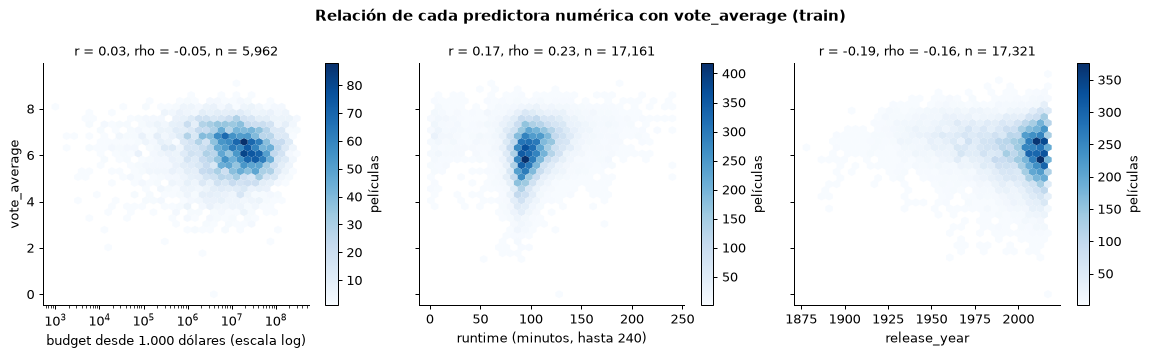

,n,Pearson,Spearman,Spearman en train por grupos
predictora,,,,
budget,5962,0.029,-0.046,-0.037
runtime,17161,0.168,0.229,0.241
release_year,17321,-0.187,-0.163,-0.165


In [5]:
fig, ejes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
ajustes = {
    "budget": {"xscale": "log", "etiqueta": "budget desde 1.000 dólares (escala log)"},
    "runtime": {"xscale": "linear", "etiqueta": "runtime (minutos, hasta 240)"},
    "release_year": {"xscale": "linear", "etiqueta": "release_year"},
}
filas_corr = []
for eje, columna in zip(ejes, NUMERICAS):
    pares_xy = train_r[[columna, OBJETIVO]].dropna()
    r = pares_xy[columna].corr(pares_xy[OBJETIVO], method="pearson")
    rho = pares_xy[columna].corr(pares_xy[OBJETIVO], method="spearman")
    filas_corr.append({"predictora": columna, "n": len(pares_xy), "Pearson": r, "Spearman": rho})

    a_graficar = pares_xy[pares_xy["runtime"] <= 240] if columna == "runtime" else pares_xy
    a_graficar = a_graficar[a_graficar[columna] >= 1000] if columna == "budget" else a_graficar
    malla = eje.hexbin(
        a_graficar[columna], a_graficar[OBJETIVO], gridsize=32, cmap="Blues",
        xscale=ajustes[columna]["xscale"], mincnt=1, linewidths=0,
    )
    eje.set_xlabel(ajustes[columna]["etiqueta"])
    eje.set_title(f"r = {r:.2f}, rho = {rho:.2f}, n = {len(pares_xy):,}", fontsize=10)
    eje.grid(False)
    fig.colorbar(malla, ax=eje, label="películas")
ejes[0].set_ylabel("vote_average")
fig.suptitle("Relación de cada predictora numérica con vote_average (train)", fontweight="bold")
fig.tight_layout()
plt.show()

tabla_corr = pd.DataFrame(filas_corr).set_index("predictora")
tabla_corr["Spearman en train por grupos"] = [
    train_g[columna].corr(train_g[OBJETIVO], method="spearman") for columna in NUMERICAS
]
tabla_corr.round(3)

- `runtime` es la relación más clara (Spearman 0,229): las películas más largas tienden a calificarse mejor. La de `release_year` es negativa (−0,163): las películas antiguas que llegan a más de 10 votos tienden a estar mejor calificadas, lo que puede ser un sesgo de selección y no un efecto del año.
- `budget` casi no se relaciona con la calificación (Pearson 0,029, Spearman −0,046).
- Pearson y Spearman difieren en `runtime` y en `budget`, lo que indica relaciones no lineales o valores extremos.
- Con el train por grupos los valores son casi iguales, así que la conclusión no depende de la partición.

### 1.3 `vote_average` por género e idioma

Las categorías raras se agrupan con la lista que aprendió el `OneHotEncoder` ajustado con train, no con un cálculo aparte. Los nulos de idioma se reemplazan por la moda, como en el Pipeline.

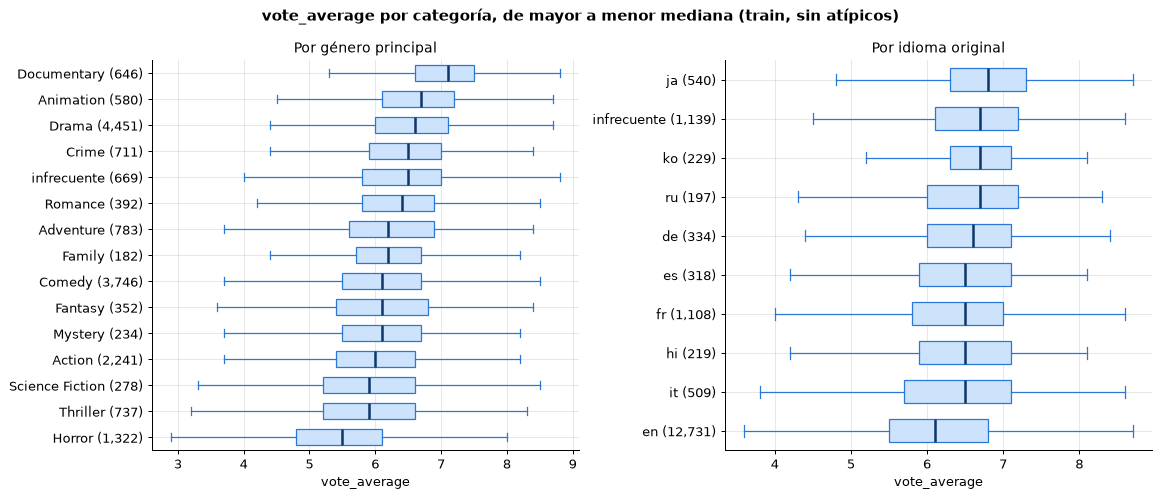

,n,media,mediana
genero,,,
Documentary,646,7.035,7.1
Animation,580,6.631,6.7
Drama,4451,6.494,6.6
Crime,711,6.433,6.5
infrecuente,669,6.414,6.5
Romance,392,6.294,6.4
Adventure,783,6.162,6.2
Family,182,6.195,6.2
Comedy,3746,6.081,6.1


In [6]:
prepro = modelo_r.named_steps["preprocesamiento"]
inf_genero = set(prepro.named_transformers_["genero"].named_steps["codificar"].infrequent_categories_[0])
inf_idioma = set(prepro.named_transformers_["idioma"].named_steps["codificar"].infrequent_categories_[0])
moda_idioma = prepro.named_transformers_["idioma"].named_steps["imputar"].statistics_[0]

grupos_cat = pd.DataFrame({
    "genero": train_r["genero_principal"].where(~train_r["genero_principal"].isin(inf_genero), "infrecuente"),
    "idioma": train_r["original_language"].fillna(moda_idioma)
        .where(lambda s: ~s.isin(inf_idioma), "infrecuente"),
    OBJETIVO: train_r[OBJETIVO],
})


def resumen(columna):
    tabla = grupos_cat.groupby(columna)[OBJETIVO].agg(n="count", media="mean", mediana="median")
    return tabla.sort_values("mediana", ascending=False).round(3)


def cajas(eje, columna, titulo):
    tabla = resumen(columna).iloc[::-1]
    datos = [grupos_cat.loc[grupos_cat[columna] == c, OBJETIVO] for c in tabla.index]
    eje.boxplot(
        datos, orientation="horizontal", tick_labels=[f"{c} ({n:,})" for c, n in zip(tabla.index, tabla["n"])],
        showfliers=False, patch_artist=True, widths=0.6,
        boxprops={"facecolor": "#cde2fb", "edgecolor": COLOR_PRINCIPAL},
        medianprops={"color": "#0d366b", "linewidth": 2},
        whiskerprops={"color": COLOR_PRINCIPAL}, capprops={"color": COLOR_PRINCIPAL},
    )
    eje.set_xlabel("vote_average")
    eje.set_title(titulo, fontsize=11)


fig, ejes = plt.subplots(1, 2, figsize=(13, 5.6))
cajas(ejes[0], "genero", "Por género principal")
cajas(ejes[1], "idioma", "Por idioma original")
fig.suptitle("vote_average por categoría, de mayor a menor mediana (train, sin atípicos)", fontweight="bold")
fig.tight_layout()
plt.show()
resumen("genero")

In [7]:
resumen("idioma")

,n,media,mediana
idioma,,,
ja,540,6.796,6.8
infrecuente,1139,6.609,6.7
ko,229,6.720,6.7
ru,197,6.598,6.7
de,334,6.459,6.6
es,318,6.411,6.5
fr,1108,6.391,6.5
hi,219,6.432,6.5
it,509,6.404,6.5


- **Género:** hay diferencias amplias. `Documentary` tiene la mayor mediana (7,1) y `Horror` la menor (5,5).
- **Idioma:** `en` tiene la mediana más baja (6,1), frente a 6,5 o más en todos los demás grupos. Es un 73 % del train, y es probable que las películas en otros idiomas que superan 10 votos en TMDB sean una selección más favorable; este análisis no permite afirmar que sea un efecto del idioma.
- Las dos variables separan la calificación más que `budget`, en línea con la importancia que les dio el modelo en la Fase 1.

### 1.4 Franquicia y presupuesto faltante

In [8]:
def por_grupo(serie, nombres):
    tabla = train_r.groupby(serie.map(nombres))[OBJETIVO].agg(n="count", media="mean", mediana="median", desviacion="std")
    tabla.index.name = None
    return tabla.round(3)


print("Según es_franquicia"); print(por_grupo(train_r["es_franquicia"], {0: "sin colección", 1: "con colección"}).to_string())

budget_nulo = train_r["budget"].isna()
print(f"\nbudget nulo en train: {budget_nulo.mean():.1%}")
print("\nSegún budget"); print(por_grupo(budget_nulo, {False: "budget reportado", True: "budget nulo"}).to_string())

a, b = train_r.loc[~budget_nulo, OBJETIVO], train_r.loc[budget_nulo, OBJETIVO]
desv_comb = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
print(f"\nDiferencia de medias (reportado - nulo): {a.mean() - b.mean():.3f}, d de Cohen: {(a.mean() - b.mean()) / desv_comb:.3f}")

perfil = train_r.groupby(budget_nulo.map({False: "budget reportado", True: "budget nulo"}))[["runtime", "release_year", "es_franquicia"]].agg(
    {"runtime": "median", "release_year": "median", "es_franquicia": "mean"}).round(3)
perfil.index.name = None
print("\nPerfil de cada grupo"); print(perfil.to_string())

periodo = pd.cut(train_r["release_year"], bins=[0, 1979, 1999, 2009, 2100], labels=["hasta 1979", "1980-1999", "2000-2009", "2010 en adelante"])
por_periodo = train_r.groupby([periodo, budget_nulo.map({False: "reportado", True: "nulo"})], observed=True)[OBJETIVO].agg(["count", "mean"]).unstack().round(3)
por_periodo["diferencia (reportado - nulo)"] = (por_periodo[("mean", "reportado")] - por_periodo[("mean", "nulo")]).round(3)
print("\nPor periodo"); print(por_periodo.to_string())

Según es_franquicia
                   n  media  mediana  desviacion
con colección   2700  6.029      6.1       1.026
sin colección  14624  6.222      6.3       0.976

budget nulo en train: 65.6%

Según budget
                      n  media  mediana  desviacion
budget nulo       11362  6.201      6.3       1.002
budget reportado   5962  6.176      6.2       0.956

Diferencia de medias (reportado - nulo): -0.024, d de Cohen: -0.025

Perfil de cada grupo
                  runtime  release_year  es_franquicia
budget nulo          96.0        2004.0          0.131
budget reportado    103.0        2005.0          0.204

Por periodo
                 count             mean           diferencia (reportado - nulo)
budget            nulo reportado   nulo reportado                              
release_year                                                                   
hasta 1979        2528       613  6.565     6.733                         0.168
1980-1999         2368      1491  6.108     6

- **`es_franquicia`:** las películas con colección tienen una media 0,19 menor que las demás (6,029 frente a 6,222). La sección 3 muestra que ese grupo mezcla dos comportamientos opuestos.
- **`budget` nulo:** en conjunto, faltar casi no dice nada sobre la calificación: la diferencia de medias es −0,024 y la d de Cohen −0,025. Pero sí dice algo sobre la película: las que no lo reportan son más cortas (mediana de 96 frente a 103 minutos) y menos veces de colección (13,1 % frente a 20,4 %).
- **El efecto cambia con la época:** hasta 1999, las películas con presupuesto reportado están mejor calificadas (+0,17 y +0,13); desde 2000 la diferencia casi desaparece (−0,04 y −0,03). Por eso conviene conservar el indicador de faltante: un modelo de árboles puede usar esa interacción con el año, aunque el promedio global no la muestre.

### Conclusiones de C1

1. Las predictoras numéricas no son redundantes entre sí; la mayor correlación es 0,323 (Spearman, `budget` y `runtime`).
2. `runtime` y `release_year` son las numéricas con relación más clara con `vote_average`; `budget` casi no tiene relación directa.
3. `genero_principal` y `original_language` separan bien la calificación, con el inglés como el grupo más bajo.
4. Que falte `budget` no cambia la calificación promedio, pero se relaciona con la época y con el tipo de película.
5. La importancia por permutación de la Fase 1 no reemplaza este análisis: mide de qué depende el modelo ya ajustado sobre prueba, no cómo se relacionan los datos ni si hay redundancias. Estas cifras son asociaciones, no efectos causales.

## 2. Sagas compartidas (C2)

En la partición de la Fase 1 hay películas de una misma saga en entrenamiento y en prueba. Si el modelo va a usarse con sagas nuevas, esa evaluación puede ser optimista. `make_groups` asigna a cada película su colección, o la deja como su propio grupo si no tiene. La estrategia `group` usa `GroupShuffleSplit`.

### 2.1 Grupos y tamaños reales

In [9]:
def colecciones(tabla):
    return set(features.collection_ids(tabla).dropna().astype(int))


filas = []
for nombre, train, test in (("random", train_r, test_r), ("group", train_g, test_g)):
    compartidas = colecciones(train) & colecciones(test)
    filas.append({
        "estrategia": nombre, "filas train": len(train), "filas prueba": len(test),
        "% filas prueba": round(len(test) / len(df) * 100, 2),
        "colecciones train": len(colecciones(train)), "colecciones prueba": len(colecciones(test)),
        "colecciones en ambos lados": len(compartidas),
        "pelis de prueba en colección vista": int(features.collection_ids(test).isin(compartidas).sum()),
        "media objetivo prueba": round(test[OBJETIVO].mean(), 3),
        "% con colección en prueba": round(test["es_franquicia"].mean() * 100, 2),
    })
tabla_particion = pd.DataFrame(filas).set_index("estrategia").T
assert tabla_particion.loc["colecciones en ambos lados", "group"] == 0
tabla_particion

estrategia,random,group
filas train,17324.000,17335.000
filas prueba,4332.000,4321.000
% filas prueba,20.000,19.950
colecciones train,1280.000,1112.000
colecciones prueba,565.000,264.000
colecciones en ambos lados,469.000,0.000
pelis de prueba en colección vista,604.000,0.000
media objetivo prueba,6.172,6.213
% con colección en prueba,16.940,15.390


- `random` deja **469 colecciones en ambos lados**, lo que confirma la cifra del profesor, y 604 películas de prueba pertenecen a una colección vista. `group` deja **0**.
- `GroupShuffleSplit` reparte grupos, no filas. Aun así, los tamaños reales quedaron casi iguales: 17.335 en train y 4.321 en prueba (19,95 %), porque la mayoría de los grupos son películas sueltas.
- Las dos pruebas tienen películas distintas, así que sus métricas no se comparan fila a fila. La media del objetivo y la proporción con colección difieren un poco.

### 2.2 Comparación de HGB y baseline

Mismos hiperparámetros y semilla. Cada estrategia usa su propia CV dentro de su train: `KFold` en `random` y `GroupKFold` en `group`.

In [10]:
def metricas(y, pred):
    return {"MAE": mean_absolute_error(y, pred), "RMSE": root_mean_squared_error(y, pred), "R2": r2_score(y, pred)}


def evaluar(estrategia, train, test, sexta=SEXTA_FASE1, modelos=("HGB", "Baseline")):
    columnas = list(config.get_feature_names(sexta))
    fabricas = {
        "HGB": lambda: hgb_paso2(config.SEED, sexta),
        "Baseline": lambda: pipeline.build_baseline(sexta),
    }
    filas = []
    for nombre in modelos:
        cv = splitting.cross_validate_model(fabricas[nombre](), train, estrategia, columnas, config.SEED)
        ajustado = fabricas[nombre]().fit(train[columnas], train[OBJETIVO])
        prueba = metricas(test[OBJETIVO], ajustado.predict(test[columnas]))
        iteraciones = getattr(ajustado.named_steps["modelo"], "n_iter_", None)
        filas.append({"estrategia": estrategia, "sexta": sexta, "modelo": nombre, "iteraciones": iteraciones,
                      "CV MAE": cv["MAE"], "CV RMSE": cv["RMSE"], "CV RMSE desv": cv["RMSE_desv"], "CV R2": cv["R2"],
                      "prueba MAE": prueba["MAE"], "prueba RMSE": prueba["RMSE"], "prueba R2": prueba["R2"]})
    return pd.DataFrame(filas)


comparacion = pd.concat([evaluar("random", train_r, test_r), evaluar("group", train_g, test_g)], ignore_index=True)
print(comparacion.drop(columns="sexta").set_index(["modelo", "estrategia"]).sort_index(ascending=[False, False]).round(4).T.to_string())

modelo             HGB          Baseline        
estrategia      random    group   random   group
iteraciones   100.0000  92.0000      NaN     NaN
CV MAE          0.6170   0.6187   0.7771  0.7776
CV RMSE         0.7989   0.7981   0.9865  0.9852
CV RMSE desv    0.0072   0.0208   0.0058  0.0176
CV R2           0.3440   0.3433  -0.0002 -0.0008
prueba MAE      0.6059   0.6205   0.7823  0.7854
prueba RMSE     0.7813   0.8028   0.9880  0.9930
prueba R2       0.3745   0.3457  -0.0004 -0.0010


- **En CV no hay caída:** el RMSE de HGB es 0,7981 con grupos frente a 0,7989 sin ellos. El MAE sube 0,0017 y el R² baja 0,0007.
- **En prueba sí baja:** el RMSE pasa de 0,7813 a 0,8028 y el R² de 0,3745 a 0,3457. Pero la prueba por grupos también es más difícil para el baseline (RMSE de 0,9880 a 0,9930), y la sección 5 muestra que esa diferencia está exagerada con la semilla 42.
- **HGB supera al baseline con las dos estrategias:** reduce el RMSE un 20,9 % con `random` y un 19,2 % con `group`.
- **Desviación entre folds:** con grupos es 0,0208, frente a 0,0072. Una revisión por fold mostró que `GroupKFold` deja un fold más difícil (RMSE de 0,8387 y baseline de 1,0201); no es un error del código.
- **Parada temprana:** con grupos, HGB se detuvo en 92 iteraciones. Su validación interna es aleatoria y no respeta grupos: dentro de train sí puede ver una saga en ambos lados. Ese límite no afecta a la prueba, pero queda como riesgo para el Paso 3.

Sobre C4: la cercanía entre CV y prueba de la Fase 1 no descarta un efecto de la partición. Con `random`, prueba quedó mejor que CV (0,7813 frente a 0,7989); con `group`, peor (0,8028 frente a 0,7981). Es evidencia favorable, no una garantía.

## 3. `es_franquicia` al momento del estreno (C3)

`es_franquicia` vale 1 si la película pertenece a una colección de TMDB. Esa colección puede haberse creado después del estreno: una película exitosa recibe secuelas y entonces entra en una colección. Si es así, para la primera película de cada saga la variable no se conocía al estrenarse.

`es_secuela` usa solo lo que sí se conoce al estreno: si ya existía una película anterior de la misma colección.

- Vale 1 si en su colección existe otra película con `release_date` estrictamente anterior.
- Vale 0 si no tiene colección o si es la primera.
- **Empates:** si varias comparten la primera fecha, todas valen 0, porque ninguna es estrictamente anterior.
- **Fechas nulas:** una película con fecha nula vale 0, porque no se puede afirmar que sea secuela. Una fecha nula de otra película de la colección no cuenta como anterior.
- Se calcula sobre el dataset limpio, antes de los filtros: una precuela con pocos votos sigue siendo precuela.

### 3.1 Estructura de las colecciones

Estos conteos no miran el objetivo. Se calculan sobre el dataset limpio, que es sobre el que se define `es_secuela`, y se repiten sobre la población del modelo.

In [11]:
def estructura(tabla, nombre):
    ids = features.collection_ids(tabla)
    con_coleccion = tabla[ids.notna()].assign(coleccion=ids.dropna().astype(int))
    fechas = pd.to_datetime(con_coleccion["release_date"], errors="coerce")
    primera = fechas.groupby(con_coleccion["coleccion"]).transform("min")
    es_primera = fechas == primera
    empatadas = es_primera & es_primera.groupby([con_coleccion["coleccion"]]).transform("sum").gt(1)
    tamano = con_coleccion.groupby("coleccion").size()
    return {
        "conjunto": nombre, "películas con colección": len(con_coleccion),
        "colecciones": len(tamano),
        "primeras de su colección": int(es_primera.sum()),
        "% primeras": round(es_primera.mean() * 100, 1),
        "de ellas, empatadas en la primera fecha": int(empatadas.sum()),
        "con fecha nula": int(fechas.isna().sum()),
        "colecciones con una sola película": int((tamano == 1).sum()),
        "% colecciones de una película": round((tamano == 1).mean() * 100, 1),
        "es_secuela = 1 (definida en el limpio)": int(con_coleccion["es_secuela"].sum()),
    }


pd.DataFrame([estructura(limpio, "limpio"), estructura(df, "población")]).set_index("conjunto").T

conjunto,limpio,población
películas con colección,4487.0,3434.0
colecciones,1695.0,1376.0
primeras de su colección,1704.0,1382.0
% primeras,38.0,40.2
"de ellas, empatadas en la primera fecha",15.0,10.0
con fecha nula,2.0,0.0
colecciones con una sola película,390.0,337.0
% colecciones de una película,23.0,24.5
es_secuela = 1 (definida en el limpio),2781.0,2082.0


In [12]:
ids_limpio = features.collection_ids(limpio)
tam_limpio = ids_limpio.map(ids_limpio.value_counts())
en_poblacion = limpio["id"].isin(df["id"])

fechas_pob = pd.to_datetime(df["release_date"], errors="coerce")
primera_en_pob = fechas_pob == fechas_pob.groupby(features.collection_ids(df)).transform("min")

print(f"Únicas de su colección en el limpio y presentes en la población: {int((en_poblacion & (tam_limpio == 1)).sum()):,}")
print(f"Primeras dentro de la población, con precuela quitada por los filtros: {int((df['es_secuela'].eq(1) & primera_en_pob).sum()):,}")

sola = limpio[tam_limpio == 1]
ejemplos = sola[["title", "release_date"]].assign(
    coleccion=sola["belongs_to_collection"].str.extract(r"'name': '([^']+)'")[0]
)
print("\nEjemplos de colecciones con una sola película:")
print(ejemplos.head(8).to_string(index=False))

Únicas de su colección en el limpio y presentes en la población: 207
Primeras dentro de la población, con precuela quitada por los filtros: 30

Ejemplos de colecciones con una sola película:
             title release_date                      coleccion
         Showgirls   1995-09-22           Showgirls Collection
Once Were Warriors   1994-09-02  Once were Warriors Collection
       Ri¢hie Ri¢h   1994-12-19         Richie Rich Collection
          The Fear   1995-01-20                Fear Collection
      Blade Runner   1982-06-25        Blade Runner Collection
        Alphaville   1965-05-05       Lemmy Caution Collection
        Yes, Madam   1985-01-01 In the Line of Duty Collection
Warriors of Virtue   1997-05-02  Warriors of Virtue Collection


- **Primeras de su colección:** 1.704 de las 4.487 películas con colección del dataset limpio (38,0 %); 15 de ellas empatan en la primera fecha. Para ese 38 %, `es_franquicia` vale 1 aunque quizá la colección no existía al estrenarse.
- **Colecciones de una sola película:** 390 de 1.695 (23,0 %) en el limpio. *Blade Runner* (1982) está en este grupo: figura en una colección sin que el dataset tenga otra película de ella.
- **`es_secuela` no es perfecta:** si la película anterior de la saga no está en el dataset, queda en 0. Eso puede afectar a parte de las 207 películas de la población que son las únicas de su colección.
- **Por qué se calcula antes de los filtros:** 30 películas de la población serían "primeras" si se mirara solo la población, pero tienen una precuela que los filtros quitaron. Por eso la fila de la población muestra 1.382 primeras dentro de ese conjunto, mientras que según `es_secuela` son 1.352.
- Dos películas con colección tienen fecha nula en el limpio; ninguna llega a la población.

### 3.2 `es_franquicia` frente a `es_secuela`

Distribución y relación con el objetivo sobre el train de la partición por grupos, porque es la que corresponde a esta comparación.

Distribución en train (grupos):
es_franquicia    15.97 % en 1
es_secuela        9.67 % en 1

Cruce (filas):
es_secuela         0     1
es_franquicia             
0              14566     0
1               1092  1677

vote_average por grupo:
                             n  media  mediana  desviacion
sin colección            14566  6.212      6.3       0.975
primera de su colección   1092  6.318      6.4       0.904
secuela                   1677  5.830      5.9       1.047
es_franquicia: Pearson con vote_average = -0.070
es_secuela: Pearson con vote_average = -0.117


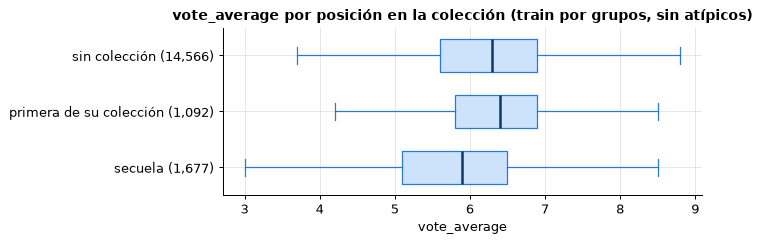

In [13]:
print("Distribución en train (grupos):")
print((train_g[["es_franquicia", "es_secuela"]].mean() * 100).round(2).astype(str).add(" % en 1").to_string())
print("\nCruce (filas):")
print(pd.crosstab(train_g["es_franquicia"], train_g["es_secuela"]).to_string())

tres = pd.Series("sin colección", index=train_g.index)
tres[train_g["es_franquicia"].eq(1) & train_g["es_secuela"].eq(0)] = "primera de su colección"
tres[train_g["es_secuela"].eq(1)] = "secuela"
orden = ["sin colección", "primera de su colección", "secuela"]
tabla_tres = train_g.groupby(tres)[OBJETIVO].agg(n="count", media="mean", mediana="median", desviacion="std").loc[orden].round(3)
tabla_tres.index.name = None
print("\nvote_average por grupo:"); print(tabla_tres.to_string())

for nombre in ("es_franquicia", "es_secuela"):
    print(f"{nombre}: Pearson con vote_average = {train_g[nombre].corr(train_g[OBJETIVO]):.3f}")

fig, eje = plt.subplots(figsize=(8, 2.8))
datos = [train_g.loc[tres == g, OBJETIVO] for g in orden[::-1]]
eje.boxplot(datos, orientation="horizontal", tick_labels=[f"{g} ({tabla_tres.loc[g, 'n']:,})" for g in orden[::-1]],
            showfliers=False, patch_artist=True, widths=0.6,
            boxprops={"facecolor": "#cde2fb", "edgecolor": COLOR_PRINCIPAL},
            medianprops={"color": "#0d366b", "linewidth": 2},
            whiskerprops={"color": COLOR_PRINCIPAL}, capprops={"color": COLOR_PRINCIPAL})
eje.set_xlabel("vote_average")
eje.set_title("vote_average por posición en la colección (train por grupos, sin atípicos)", fontweight="bold", fontsize=11)
fig.tight_layout()
plt.show()

La separación en tres grupos explica el resultado de 1.4. Las primeras películas de una colección tienen la mejor media (6,318), mejor incluso que las películas sin colección (6,212), mientras que las secuelas tienen la peor (5,830). Es lo esperable si las películas bien recibidas son las que generan sagas, aunque este análisis no lo demuestra.

`es_franquicia` junta esos dos grupos: el 39,4 % de sus unos (1.092 de 2.769) son primeras películas. `es_secuela` los separa y su correlación con el objetivo es más alta en magnitud (−0,117 frente a −0,070).

### 3.3 Métricas con partición por grupos

In [14]:
sextas = pd.concat([
    evaluar("group", train_g, test_g, sexta, modelos=("HGB",)) for sexta in config.SIXTH_FEATURE_OPTIONS
], ignore_index=True)
print(sextas.drop(columns=["estrategia", "modelo"]).set_index("sexta").round(4).T.to_string())

sexta         es_franquicia  es_secuela
iteraciones         92.0000     64.0000
CV MAE               0.6187      0.6153
CV RMSE              0.7981      0.7949
CV RMSE desv         0.0208      0.0216
CV R2                0.3433      0.3486
prueba MAE           0.6205      0.6187
prueba RMSE          0.8028      0.8007
prueba R2            0.3457      0.3491


Con la misma partición por grupos, `es_secuela` mejora un poco: el RMSE baja 0,0032 en CV y 0,0021 en prueba. Es una diferencia pequeña, menor que la desviación entre folds (0,02), aunque la sección 5 muestra que es consistente. Las iteraciones son distintas (92 y 64), así que parte de la diferencia puede venir de la parada temprana.

## 4. Horizonte del objetivo (C5)

`vote_average` no es una calificación "final": es el promedio acumulado hasta el momento en que se descargaron los datos de TMDB. Para interpretarlo hace falta saber cuándo fue eso.

### 4.1 Filas que quita cada filtro

In [15]:
estrenada = limpio[config.STATUS_COLUMN] == config.STATUS_RELEASED
votos = limpio[config.VOTE_COUNT_COLUMN] > config.MIN_VOTES
pd.DataFrame([
    {"paso": "CSV crudo", "filas": len(crudo)},
    {"paso": "limpieza (reglas 1 a 4)", "quita": len(crudo) - len(limpio), "filas": len(limpio)},
    {"paso": "status Released, aplicado primero", "quita": int((~estrenada).sum()), "filas": int(estrenada.sum())},
    {"paso": "vote_count > 10, después de status", "quita": int((estrenada & ~votos).sum()), "filas": int((estrenada & votos).sum())},
    {"paso": "vote_count > 10, aplicado solo", "quita": int((~votos).sum()), "filas": int(votos.sum())},
    {"paso": "status Released, después de votos", "quita": int((~estrenada & votos).sum()), "filas": int((estrenada & votos).sum())},
]).set_index("paso").fillna(0).astype(int)

,filas,quita
paso,,
CSV crudo,45466,0
limpieza (reglas 1 a 4),45430,36
"status Released, aplicado primero",44985,445
"vote_count > 10, después de status",21656,23329
"vote_count > 10, aplicado solo",21744,23686
"status Released, después de votos",21656,88


### 4.2 Fechas de estreno y fecha de corte

In [16]:
fechas = pd.to_datetime(limpio["release_date"], errors="coerce")
CORTE_DOCUMENTADO = pd.Timestamp("2017-07-31")
tardias = limpio.assign(fecha=fechas, en_poblacion=estrenada & votos)[fechas > CORTE_DOCUMENTADO]

conteo = pd.DataFrame({
    "limpio": {"fecha máxima": str(fechas.max().date()), "después de 2017-07-31": len(tardias),
               "después de 2017": int((fechas.dt.year > 2017).sum())},
    "status Released": {"fecha máxima": str(fechas[estrenada].max().date()), "después de 2017-07-31": int((tardias["status"] == "Released").sum()),
                        "después de 2017": int(((fechas.dt.year > 2017) & estrenada).sum())},
    "población": {"fecha máxima": str(fechas[estrenada & votos].max().date()), "después de 2017-07-31": int(tardias["en_poblacion"].sum()),
                  "después de 2017": int(((fechas.dt.year > 2017) & estrenada & votos).sum())},
})
print(conteo.to_string())
print("\nPosteriores a 2017 en el limpio:")
print(tardias[tardias["fecha"].dt.year > 2017][["title", "release_date", "status", "vote_count"]].sort_values("release_date").to_string(index=False))
print("\nPosteriores a julio de 2017 que quedan en la población:")
print(tardias[tardias["en_poblacion"]][["title", "release_date", "status", "vote_count"]].sort_values("release_date").to_string(index=False))
por_mes = fechas[estrenada & votos & (fechas >= "2016-11-01")].dt.to_period("M").value_counts().sort_index()
print("\nPelículas de la población por mes de estreno:")
print(por_mes.to_string())

                           limpio status Released   población
fecha máxima           2020-12-16      2017-12-27  2017-10-27
después de 2017-07-31          40              25          12
después de 2017                 6               0           0

Posteriores a 2017 en el limpio:
                     title release_date          status  vote_count
 Iron Sky: The Coming Race   2018-03-01 Post Production         0.0
              Mobile Homes   2018-04-04 Post Production         1.0
              Mary Shelley   2018-04-25 Post Production         1.0
         Bad Boys for Life   2018-11-07         Planned        12.0
The Other Side of the Wind   2018-12-31 Post Production         1.0
                  Avatar 2   2020-12-16   In Production        58.0

Posteriores a julio de 2017 que quedan en la población:
                                       title release_date   status  vote_count
                       S.W.A.T.: Under Siege   2017-08-01 Released        21.0
                           

**De dónde sale la fecha.**

- **Documentación:** la descripción del dataset dice que incluye películas "released on or before July 2017". Se consultó en réplicas ([hyper.ai](https://hyper.ai/en/datasets/34654) y [Baselight](https://baselight.app/u/kaggle/dataset/rounakbanik_the_movies_dataset)), porque la página de Kaggle no entregó su descripción a la herramienta de lectura. Esa frase delimita qué películas entran, no cuándo se descargaron los votos.
- **Máximo de `release_date`:** en la población es 2017-10-27 (*Call Me by Your Name*).

**Las fechas de hasta 2020 no sobreviven a los filtros.** Las 6 películas posteriores a 2017 no están estrenadas. Dos de ellas superan los 10 votos (*Avatar 2*, con 58, y *Bad Boys for Life*, con 12), así que las quita el filtro de `status`, no el de votos.

**La fecha no coincide del todo.** En la población quedan 12 películas posteriores a julio de 2017, y algunas ya tienen muchos votos (*The Dark Tower*, 688, y *What Happened to Monday*, 598). Eso sugiere que los votos se descargaron después de julio de 2017, pero no da una fecha exacta. Algunas pueden tener estrenos previos en festivales u otros países.

**Conclusión: la fecha de corte de `vote_average` queda como "no verificada".** Lo único documentado es que el dataset cubre películas hasta julio de 2017, según réplicas de su descripción. Por eso `TARGET_HORIZON` sigue en `no verificado`.

**Qué implica.** El horizonte no es igual para todas las películas: una de 1995 acumuló votos durante más de 20 años y una de 2017, unas semanas o meses. El modelo predice el promedio acumulado hasta esa fecha desconocida, solo para películas estrenadas que superaron 10 votos, no la calificación definitiva.

## 5. Sensibilidad a la semilla

Las secciones 2 y 3 comparan una sola partición, la de la semilla 42. Esta sección repite la comparación con 10 semillas, y cambia a la vez la partición y la semilla del modelo. Solo se usa el RMSE de prueba, y esta comparación no se usa para ajustar nada.

In [17]:
filas = []
for semilla in range(10):
    tr_r, te_r = splitting.split_data(df, "random", config.TEST_SIZE, semilla)
    tr_g, te_g = splitting.split_data(df, "group", config.TEST_SIZE, semilla)
    fila = {"semilla": semilla}
    for nombre, tr, te, sexta in (
        ("random, es_franquicia", tr_r, te_r, "es_franquicia"),
        ("group, es_franquicia", tr_g, te_g, "es_franquicia"),
        ("group, es_secuela", tr_g, te_g, "es_secuela"),
    ):
        columnas = list(config.get_feature_names(sexta))
        ajustado = hgb_paso2(semilla, sexta).fit(tr[columnas], tr[OBJETIVO])
        fila[nombre] = root_mean_squared_error(te[OBJETIVO], ajustado.predict(te[columnas]))
        fila[f"iteraciones {nombre}"] = ajustado.named_steps["modelo"].n_iter_
    filas.append(fila)

sensibilidad = pd.DataFrame(filas).set_index("semilla")
rmse_cols = ["random, es_franquicia", "group, es_franquicia", "group, es_secuela"]
print(sensibilidad[rmse_cols].round(4).to_string())
print("\nMedia y desviación"); print(sensibilidad[rmse_cols].agg(["mean", "std"]).round(4).to_string())

costo_grupo = sensibilidad["group, es_franquicia"] - sensibilidad["random, es_franquicia"]
efecto_secuela = sensibilidad["group, es_secuela"] - sensibilidad["group, es_franquicia"]
iteraciones = sensibilidad[[f"iteraciones {c}" for c in rmse_cols]]
print(f"\ngroup - random: media {costo_grupo.mean():.4f}, desviación {costo_grupo.std():.4f}")
print(f"es_secuela - es_franquicia: media {efecto_secuela.mean():.4f}, desviación {efecto_secuela.std():.4f}, "
      f"gana es_secuela en {(efecto_secuela < 0).sum()} de {len(efecto_secuela)}")
print(f"Iteraciones: de {iteraciones.min().min()} a {iteraciones.max().max()}")

         random, es_franquicia  group, es_franquicia  group, es_secuela
semilla                                                                
0                       0.7975                0.7931             0.7906
1                       0.7859                0.7890             0.7871
2                       0.8010                0.8079             0.8041
3                       0.7748                0.7933             0.7901
4                       0.7931                0.8017             0.7982
5                       0.8022                0.8062             0.8044
6                       0.7886                0.8040             0.8004
7                       0.7934                0.8001             0.7969
8                       0.7906                0.8021             0.8019
9                       0.7941                0.7946             0.7890

Media y desviación
      random, es_franquicia  group, es_franquicia  group, es_secuela
mean                 0.7921                0.79

- **Partición por grupos:** en promedio cuesta 0,0071 de RMSE (desviación de 0,0068) frente a `random`. Es bastante menos que los 0,0215 de la semilla 42.
- **La prueba de la Fase 1 fue favorable:** su RMSE de 0,7813 está por debajo de la media de `random` (0,7921; desviación de 0,0079). Es evidencia directa para C4.
- **`es_secuela`:** mejora a `es_franquicia` en las 10 semillas, con una diferencia media de −0,0029 (desviación de 0,0015). Es pequeña, pero consistente.
- **Parada temprana:** el número de iteraciones varía entre 51 y 100, también con `random`. Las 100 iteraciones de la semilla 42 no eran la regla.

## 6. Resumen para la decisión del equipo

| Pregunta | Resultado |
|---|---|
| ¿Redundancia entre numéricas? | No; la mayor correlación es 0,323 (Spearman, `budget` y `runtime`) |
| ¿Faltar `budget` dice algo? | Poco en promedio (d = −0,025); cambia con la época y el tipo de película |
| Colecciones en ambos lados | 469 con `random`, 0 con `group` |
| Filas train / prueba | 17.324 / 4.332 con `random`, 17.335 / 4.321 con `group` |
| RMSE de HGB en CV | 0,7989 con `random`, 0,7981 con `group` |
| RMSE de HGB en prueba, semilla 42 | 0,7813 con `random`, 0,8028 con `group` |
| Costo medio de `group` en 10 semillas | +0,0071 de RMSE |
| Primeras de su colección | 1.704 de 4.487 (38,0 %) |
| Colecciones de una sola película | 390 de 1.695 (23,0 %) |
| Media de `vote_average` | primeras 6,318, sin colección 6,212, secuelas 5,830 |
| RMSE con grupos, `es_franquicia` y `es_secuela` | 0,7981 y 0,7949 en CV; 0,8028 y 0,8007 en prueba |
| `es_secuela` en 10 semillas | Gana las 10, por 0,0029 en promedio |
| Filtros | `status` quita 445; `vote_count` quita 23.329 después |
| Fecha de corte de `vote_average` | No verificada |

**Opciones de partición.** (a1) `group`: evalúa con sagas no vistas y responde a C2, con un costo medio pequeño en la métrica. (a2) `random`: mantiene la comparación directa con la Fase 1, pero deja 469 colecciones en ambos lados y evalúa solo sagas ya conocidas.

**Opciones de sexta predictora.** (b1) `es_secuela`: se conoce al estreno, mantiene 6 predictoras y mejora un poco, pero queda en 0 si falta la película anterior en el dataset. (b2) `es_franquicia`: mantiene el modelo de la Fase 1, pero para el 38 % de sus casos la información podría no existir al estreno.

**Decisión.** El equipo eligió `group` y `es_secuela`. La justificación y las limitaciones están en la sección "Decisiones del equipo" de `docs/decisiones.md`.